In [1]:
import matplotlib.pyplot as plt
import numpy as np

from src.environments.shuttleenvironment import (
    ShuttleEnvironment,
    ShuttleEnvironmentAction,
)
from src.solvers.shuttlevalueiteration import ShuttleValueIteration

In [2]:
SHUTTLE_CAPACITY = 15  # The capacity of the shuttle if diepatched (K)
SHUTTLE_DISPATCH_COST = 100  # The cost of dispatching a shuttle (c_f)
CUSTOMER_WAITING_COST = 2  # The cost per customer left waiting per time period (c_h)
CUSTOMER_ARRIVING_OPTIONS = [
    1,
    2,
    3,
    4,
    5,
]  # RV of number of customers arriving during time interval (A_t)
CUSTOMER_ARRIVING_PROBABILITIES = [
    1 / 5,
    1 / 5,
    1 / 5,
    1 / 5,
    1 / 5,
]  # Probs. of the RV for number of customers arriving during time interval (A_t)
GAMMA = 0.95  # Discount Factor
MAX_STATE = 200  # Number of people in station cannot exceed 200

In [3]:
shuttle_env = ShuttleEnvironment(
    shuttle_capacity=SHUTTLE_CAPACITY,
    shuttle_dispatch_cost=SHUTTLE_DISPATCH_COST,
    customer_waiting_cost=CUSTOMER_WAITING_COST,
    customer_arriving_options=CUSTOMER_ARRIVING_OPTIONS,
    customer_arriving_probabilities=CUSTOMER_ARRIVING_PROBABILITIES,
)

In [4]:
vi_solver = ShuttleValueIteration(
    env=shuttle_env, max_state=MAX_STATE, gamma=GAMMA, record_history=True
)
vi_solver.solve()

print(
    f"Converged after {len(vi_solver.deltas)} sweeps (last delta = {vi_solver.deltas[-1]:.1e})"
)

Converged after 343 sweeps (last delta = 9.9e-09)


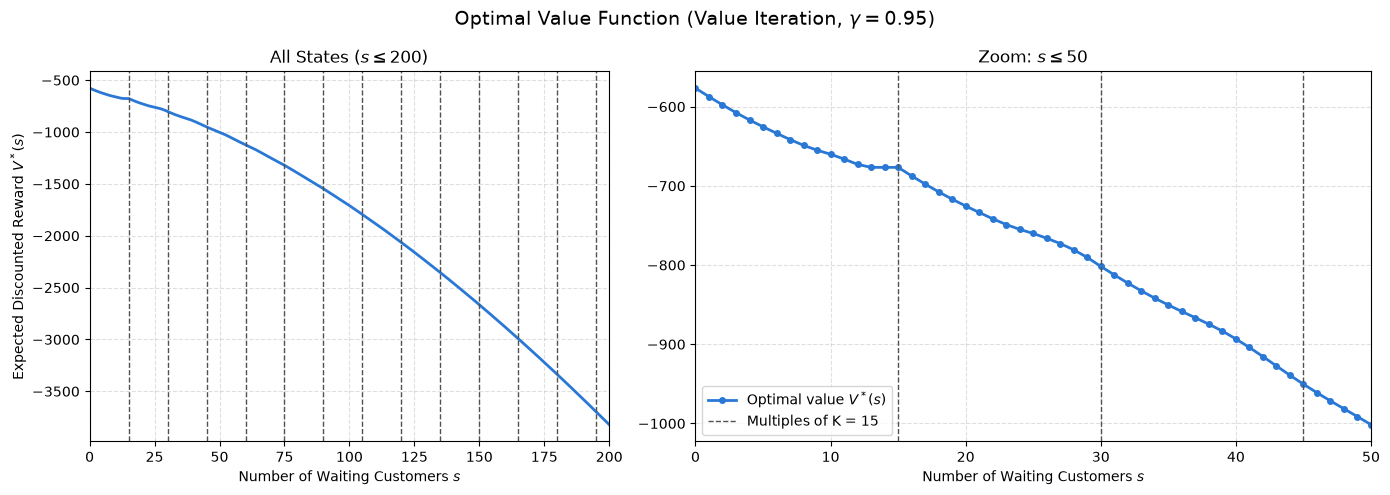

In [5]:
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
ZOOM_STATE = 50  # Right panel zooms into the states that actually occur

values = np.array(vi_solver.V)
states = np.arange(MAX_STATE + 1)

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(14, 5), width_ratios=(1, 1.3))

for ax, shown in ((ax_full, states), (ax_zoom, states[: ZOOM_STATE + 1])):
    ax.plot(
        shown,
        values[shown],
        color=BLUE,
        linewidth=2,
        marker="o" if ax is ax_zoom else None,
        markersize=4,
        label="Optimal value $V^*(s)$",
    )
    for k in range(SHUTTLE_CAPACITY, shown[-1] + 1, SHUTTLE_CAPACITY):
        ax.axvline(
            k,
            linestyle="--",
            linewidth=1,
            color=MUTED,
            label=f"Multiples of K = {SHUTTLE_CAPACITY}"
            if k == SHUTTLE_CAPACITY
            else None,
        )
    ax.set(xlabel="Number of Waiting Customers $s$", xlim=(0, shown[-1]))
    ax.grid(True, linestyle="--", alpha=0.4)

ax_full.set(
    title=f"All States ($s \\leq {MAX_STATE}$)",
    ylabel="Expected Discounted Reward $V^*(s)$",
)
ax_zoom.set(title=f"Zoom: $s \\leq {ZOOM_STATE}$")
ax_zoom.legend(loc="lower left")
fig.suptitle(
    f"Optimal Value Function (Value Iteration, $\\gamma = {GAMMA}$)", fontsize=14
)
fig.tight_layout()
plt.show()

## Checks: Reading the Policy From the Value Function
The cell below computes $Q(s, a)$ for every state and both actions, extracts the optimal policy and its dispatch threshold, and is used by the three checks that follow.

In [6]:
def report(name: str, passed: bool) -> None:
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")


# Q-values and optimal actions for every state
q = [vi_solver.q_values(s) for s in states]
q_dispatch = np.array([qs[ShuttleEnvironmentAction.DISPATCH] for qs in q])
q_wait = np.array([qs[ShuttleEnvironmentAction.WAIT] for qs in q])
dispatch = np.array(
    [vi_solver.get_action(s) == ShuttleEnvironmentAction.DISPATCH for s in states]
)

threshold = int(np.argmax(dispatch))  # First state in which dispatching is optimal
floor = values[0] - SHUTTLE_DISPATCH_COST  # Value of dispatching for every s <= K

print(f"Dispatch threshold: s >= {threshold}")
report(
    f"Policy is threshold-shaped over all {MAX_STATE + 1} states",
    not dispatch[:threshold].any() and dispatch[threshold:].all(),
)

Dispatch threshold: s >= 13
[PASS] Policy is threshold-shaped over all 201 states


### Check 1: What Does One More Waiting Customer Cost?
$V^*(s) - V^*(s-1)$ is the value of one extra waiting customer. **Expected:**
- It is never positive: an extra customer can never make things better.
- It is large near an empty station (the customer waits a long time) and shrinks towards the threshold (a shuttle is coming soon).
- It is **exactly 0 for $s = 14, 15$:** at $s \geq 13$ the optimal action is to dispatch, and up to $K = 15$ everyone fits in. An extra customer just rides along on a shuttle that leaves anyway.
- At $s = 16$ it jumps back to the cost of the very first customer: the 16th customer no longer fits and is left behind alone, like the first customer at an empty station.

[PASS] An extra customer never helps: V(s) - V(s-1) <= 0 for all s
[PASS] Customers 14..15 are free: V(s) - V(s-1) = 0
[PASS] Customer 16 costs as much as the 1st: -10.77 = -10.77


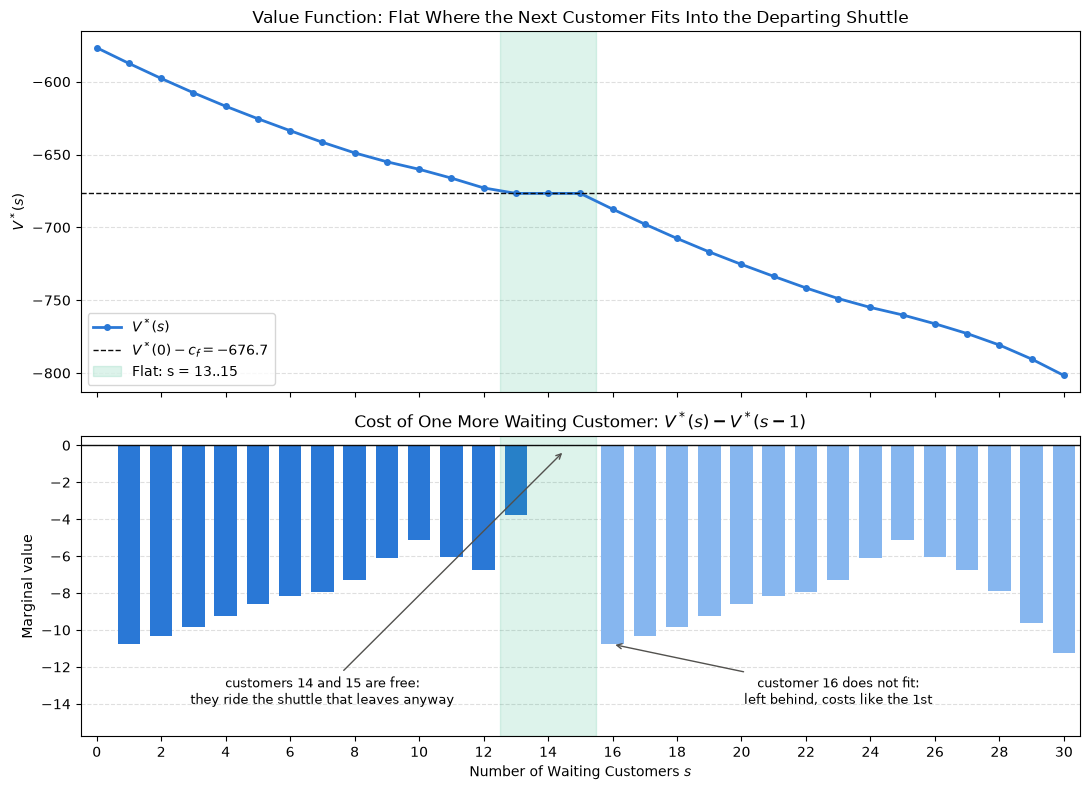

In [7]:
MARGINAL_SHOWN = 30

shown = np.arange(MARGINAL_SHOWN + 1)
marginal = (
    values[1 : MARGINAL_SHOWN + 1] - values[:MARGINAL_SHOWN]
)  # V(s) - V(s-1) for s = 1..
marginal_states = shown[1:]
free = (marginal_states > threshold) & (marginal_states <= SHUTTLE_CAPACITY)

report(
    "An extra customer never helps: V(s) - V(s-1) <= 0 for all s",
    np.all(np.diff(values) <= 1e-9),
)
report(
    f"Customers {threshold + 1}..{SHUTTLE_CAPACITY} are free: V(s) - V(s-1) = 0",
    np.allclose(marginal[free], 0),
)
report(
    f"Customer {SHUTTLE_CAPACITY + 1} costs as much as the 1st: "
    f"{values[SHUTTLE_CAPACITY + 1] - values[SHUTTLE_CAPACITY]:.2f} = {values[1] - values[0]:.2f}",
    np.isclose(
        values[SHUTTLE_CAPACITY + 1] - values[SHUTTLE_CAPACITY], values[1] - values[0]
    ),
)

fig, (ax_v, ax_m) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True, height_ratios=(1.2, 1)
)

# Top: value function with the dispatch floor
ax_v.plot(
    shown,
    values[shown],
    color=BLUE,
    linewidth=2,
    marker="o",
    markersize=4,
    label="$V^*(s)$",
)
ax_v.axhline(
    floor, linestyle="--", color=INK, linewidth=1, label=f"$V^*(0) - c_f = {floor:.1f}$"
)
ax_v.axvspan(
    threshold - 0.5,
    SHUTTLE_CAPACITY + 0.5,
    color=AQUA,
    alpha=0.15,
    label=f"Flat: s = {threshold}..{SHUTTLE_CAPACITY}",
)
ax_v.set(
    title="Value Function: Flat Where the Next Customer Fits Into the Departing Shuttle",
    ylabel="$V^*(s)$",
)
ax_v.legend(loc="lower left")

# Bottom: cost of one more customer
ax_m.bar(
    marginal_states,
    marginal,
    width=0.7,
    color=np.where(
        free, AQUA, np.where(marginal_states > SHUTTLE_CAPACITY, "#86b6ef", BLUE)
    ),
)
ax_m.axhline(0, color=INK, linewidth=1)
ax_m.axvspan(threshold - 0.5, SHUTTLE_CAPACITY + 0.5, color=AQUA, alpha=0.15)
ax_m.annotate(
    f"customers {threshold + 1} and {SHUTTLE_CAPACITY} are free:\nthey ride the shuttle that leaves anyway",
    ((threshold + 1 + SHUTTLE_CAPACITY) / 2, -0.3),
    xytext=(7, -14),
    ha="center",
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color=MUTED),
)
ax_m.annotate(
    f"customer {SHUTTLE_CAPACITY + 1} does not fit:\nleft behind, costs like the 1st",
    (SHUTTLE_CAPACITY + 1, marginal[SHUTTLE_CAPACITY]),
    xytext=(23, -14),
    ha="center",
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color=MUTED),
)
ax_m.set(
    title="Cost of One More Waiting Customer: $V^*(s) - V^*(s-1)$",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Marginal value",
    xlim=(-0.5, MARGINAL_SHOWN + 0.5),
    ylim=(marginal.min() - 4.5, 0.5),  # Room for the annotations below the bars
    xticks=range(0, MARGINAL_SHOWN + 1, 2),
)

for ax in (ax_v, ax_m):
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Check 2: Where Does DISPATCH Take Over From WAIT?
For any $s \leq K$, a dispatch takes everyone and costs $c_f$; afterwards the system is exactly where an empty station would be after waiting. Therefore

$$Q(s, \text{DISPATCH}) = -c_f + \gamma\,\mathbb{E}[V^*(A)] = V^*(0) - c_f \quad \text{for all } s \leq K,$$

a constant "floor". $Q(s, \text{WAIT})$ decreases with every extra customer. **Expected:** the policy waits as long as $Q(\text{WAIT})$ is above the floor and dispatches from the first $s$ where it falls below. That $s$ is the threshold, and it should match the threshold of 13 found by enumeration in 2a.

[PASS] Q(DISPATCH) = V(0) - c_f = -676.67 for every s <= K
[PASS] Threshold 13 is the first state where V(s) reaches V(0) - c_f
[PASS] Threshold matches enumeration in 2a (13)

  s  Q(DISPATCH)    Q(WAIT)  Q(D) - Q(W)    action
  8      -676.67    -648.86       -27.81      WAIT
  9      -676.67    -654.98       -21.69      WAIT
 10      -676.67    -660.12       -16.55      WAIT
 11      -676.67    -666.17       -10.50      WAIT
 12      -676.67    -672.89        -3.78      WAIT
 13      -676.67    -680.77         4.10  DISPATCH
 14      -676.67    -690.40        13.73  DISPATCH
 15      -676.67    -701.67        25.00  DISPATCH
 16      -687.44    -712.44        25.00  DISPATCH


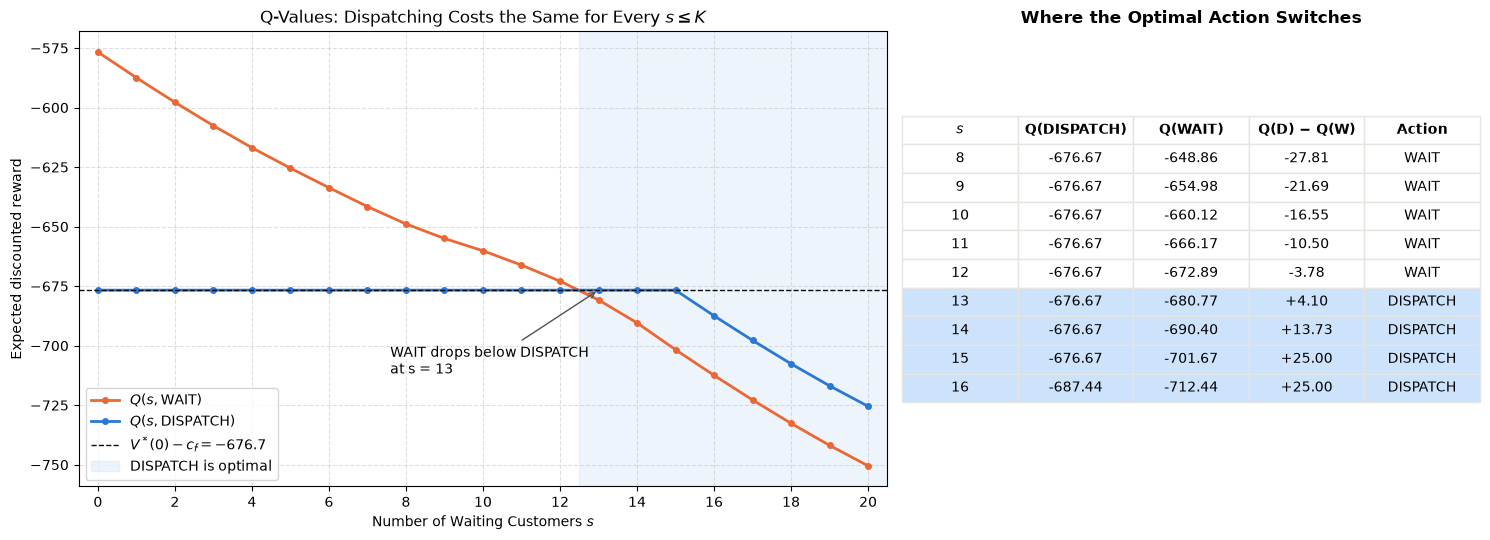

In [8]:
ENUMERATION_THRESHOLD = 13  # Steady-state threshold found in 2a_Enumeration.ipynb
Q_SHOWN = 20
TABLE_ROWS = np.arange(threshold - 5, SHUTTLE_CAPACITY + 2)  # Rows around the switch

report(
    f"Q(DISPATCH) = V(0) - c_f = {floor:.2f} for every s <= K",
    np.allclose(q_dispatch[: SHUTTLE_CAPACITY + 1], floor),
)
report(
    f"Threshold {threshold} is the first state where V(s) reaches V(0) - c_f",
    np.isclose(values[threshold], floor) and np.all(values[:threshold] > floor + 1e-6),
)
report(
    f"Threshold matches enumeration in 2a ({ENUMERATION_THRESHOLD})",
    threshold == ENUMERATION_THRESHOLD,
)

print(
    f"\n{'s':>3} {'Q(DISPATCH)':>12} {'Q(WAIT)':>10} {'Q(D) - Q(W)':>12} {'action':>9}"
)
for s in TABLE_ROWS:
    print(
        f"{s:>3} {q_dispatch[s]:>12.2f} {q_wait[s]:>10.2f} {q_dispatch[s] - q_wait[s]:>12.2f} {'DISPATCH' if dispatch[s] else 'WAIT':>9}"
    )

fig, (ax_q, ax_table) = plt.subplots(1, 2, figsize=(15, 5.5), width_ratios=(1.4, 1))

# Left: both Q-values and where they cross
shown = np.arange(Q_SHOWN + 1)
ax_q.plot(
    shown,
    q_wait[shown],
    color=ORANGE,
    linewidth=2,
    marker="o",
    markersize=4,
    label="$Q(s, \\mathrm{WAIT})$",
)
ax_q.plot(
    shown,
    q_dispatch[shown],
    color=BLUE,
    linewidth=2,
    marker="o",
    markersize=4,
    label="$Q(s, \\mathrm{DISPATCH})$",
)
ax_q.axhline(
    floor, linestyle="--", color=INK, linewidth=1, label=f"$V^*(0) - c_f = {floor:.1f}$"
)
ax_q.axvspan(
    threshold - 0.5, Q_SHOWN + 0.5, color=BLUE, alpha=0.08, label="DISPATCH is optimal"
)
ax_q.annotate(
    f"WAIT drops below DISPATCH\nat s = {threshold}",
    (threshold, q_dispatch[threshold]),
    xytext=(-150, -60),
    textcoords="offset points",
    fontsize=10,
    arrowprops=dict(arrowstyle="->", color=MUTED),
)
ax_q.set(
    title="Q-Values: Dispatching Costs the Same for Every $s \\leq K$",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Expected discounted reward",
    xlim=(-0.5, Q_SHOWN + 0.5),
    xticks=range(0, Q_SHOWN + 1, 2),
)
ax_q.grid(True, linestyle="--", alpha=0.4)
ax_q.legend(loc="lower left")

# Right: the numbers around the switch as a table
ax_table.axis("off")
cell_text = [
    [
        s,
        f"{q_dispatch[s]:.2f}",
        f"{q_wait[s]:.2f}",
        f"{q_dispatch[s] - q_wait[s]:+.2f}",
        "DISPATCH" if dispatch[s] else "WAIT",
    ]
    for s in TABLE_ROWS
]
table = ax_table.table(
    cellText=cell_text,
    colLabels=["$s$", "Q(DISPATCH)", "Q(WAIT)", "Q(D) − Q(W)", "Action"],
    loc="center",
    cellLoc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#e6e5e0")
    if row == 0:
        cell.set_text_props(fontweight="bold")
    elif dispatch[TABLE_ROWS[row - 1]]:
        cell.set_facecolor("#cde2fb")
ax_table.set_title("Where the Optimal Action Switches", fontweight="bold")

fig.tight_layout()
plt.show()

### Check 3: The Value Function Repeats Every $K = 15$ Customers
Dispatching turns $s$ waiting customers into $s - K$ for a price of $c_f$. If those $s - K$ customers are below the threshold (so the optimal action for them is to wait), the future from $s$ after dispatching is exactly the future from $s - K$ after waiting:

$$Q(s, \text{DISPATCH}) = -c_f + Q(s - K, \text{WAIT}) \quad\Rightarrow\quad V^*(s) = V^*(s - K) - c_f \quad \text{for } K \leq s < K + \text{threshold}.$$

**Expected:** for $s = 15, \dots, 27$, the curve is an exact copy of $s = 0, \dots, 12$, shifted down by 100. From $s = 28$ on, the customers left behind are themselves at the threshold and need their own shuttle soon, so the copy stops being exact and the gap grows beyond 100.

[PASS] V(s) = V(s - K) - c_f exactly for s = 15..27
[PASS] Copy breaks at s = 28 (left-behind customers already need a shuttle)


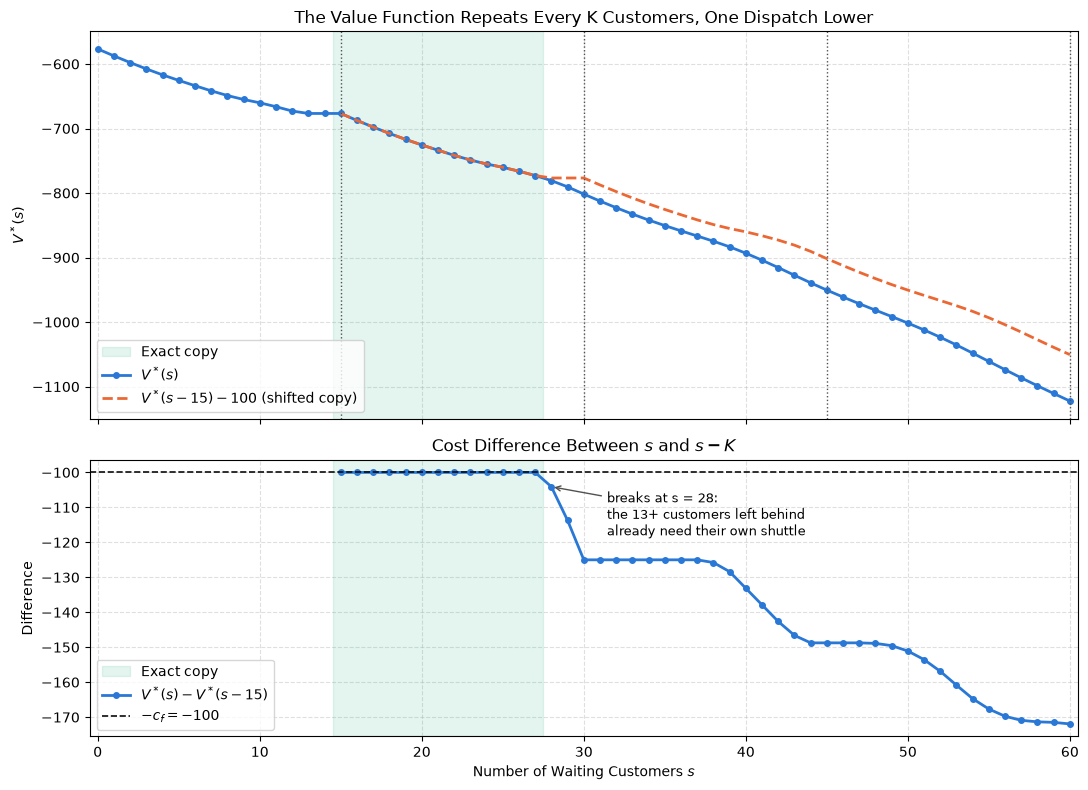

In [9]:
PERIOD_SHOWN = 60

exact_copy = np.arange(
    SHUTTLE_CAPACITY, SHUTTLE_CAPACITY + threshold
)  # s = K .. K + threshold - 1
gap = (
    values[SHUTTLE_CAPACITY : PERIOD_SHOWN + 1]
    - values[: PERIOD_SHOWN + 1 - SHUTTLE_CAPACITY]
)

report(
    f"V(s) = V(s - K) - c_f exactly for s = {exact_copy[0]}..{exact_copy[-1]}",
    np.allclose(
        values[exact_copy] - values[exact_copy - SHUTTLE_CAPACITY],
        -SHUTTLE_DISPATCH_COST,
    ),
)
report(
    f"Copy breaks at s = {SHUTTLE_CAPACITY + threshold} (left-behind customers already need a shuttle)",
    values[SHUTTLE_CAPACITY + threshold] - values[threshold]
    < -SHUTTLE_DISPATCH_COST - 1e-6,
)

fig, (ax_v, ax_gap) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True, height_ratios=(1.4, 1)
)

# Top: V(s) and its copy shifted by K to the right and by c_f down
shown = np.arange(PERIOD_SHOWN + 1)
shifted = np.arange(SHUTTLE_CAPACITY, PERIOD_SHOWN + 1)
for ax in (ax_v, ax_gap):
    ax.axvspan(
        exact_copy[0] - 0.5,
        exact_copy[-1] + 0.5,
        color=AQUA,
        alpha=0.12,
        label="Exact copy",
    )
ax_v.plot(
    shown,
    values[shown],
    color=BLUE,
    linewidth=2,
    marker="o",
    markersize=4,
    label="$V^*(s)$",
)
ax_v.plot(
    shifted,
    values[shifted - SHUTTLE_CAPACITY] - SHUTTLE_DISPATCH_COST,
    color=ORANGE,
    linewidth=2,
    linestyle="--",
    label=f"$V^*(s - {SHUTTLE_CAPACITY}) - {SHUTTLE_DISPATCH_COST}$ (shifted copy)",
)
for k in range(SHUTTLE_CAPACITY, PERIOD_SHOWN + 1, SHUTTLE_CAPACITY):
    ax_v.axvline(k, linestyle=":", linewidth=1, color=MUTED)
ax_v.set(
    title="The Value Function Repeats Every K Customers, One Dispatch Lower",
    ylabel="$V^*(s)$",
)
ax_v.legend(loc="lower left")

# Bottom: the gap between s and s - K
ax_gap.plot(
    shifted,
    gap,
    color=BLUE,
    linewidth=2,
    marker="o",
    markersize=4,
    label=f"$V^*(s) - V^*(s - {SHUTTLE_CAPACITY})$",
)
ax_gap.axhline(
    -SHUTTLE_DISPATCH_COST,
    linestyle="--",
    color=INK,
    linewidth=1.2,
    label=f"$-c_f = -{SHUTTLE_DISPATCH_COST}$",
)
ax_gap.annotate(
    f"breaks at s = {SHUTTLE_CAPACITY + threshold}:\nthe {threshold}+ customers left behind\nalready need their own shuttle",
    (SHUTTLE_CAPACITY + threshold, gap[threshold]),
    xytext=(40, -35),
    textcoords="offset points",
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color=MUTED),
)
ax_gap.set(
    title=f"Cost Difference Between $s$ and $s - K$",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Difference",
    xlim=(-0.5, PERIOD_SHOWN + 0.5),
)
ax_gap.legend(loc="lower left")

for ax in (ax_v, ax_gap):
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Check 4: Convergence
The Bellman update is a $\gamma$-contraction: every sweep shrinks the distance to $V^*$ by at least a factor $\gamma$. **Expected:**
- The largest change per sweep, $\Delta_k = \max_s |V_k(s) - V_{k-1}(s)|$, decays geometrically, i.e. it is a straight line on a log scale, at least as steep as $\gamma^k$. (The in-place updates of my implementation can make it slightly faster than $\gamma^k$.)
- Stopping at $\Delta_k < 10^{-8}$ guarantees $\max_s |V_k(s) - V^*(s)| \leq \frac{\gamma\,\Delta_k}{1 - \gamma}$.

[PASS] Delta shrinks by a factor <= gamma per sweep (median ratio over the last 100 sweeps: 0.9369)
[PASS] Stopped at delta = 9.9e-09 < 1e-08; guaranteed max |V - V*| <= gamma * delta / (1 - gamma) = 1.9e-07


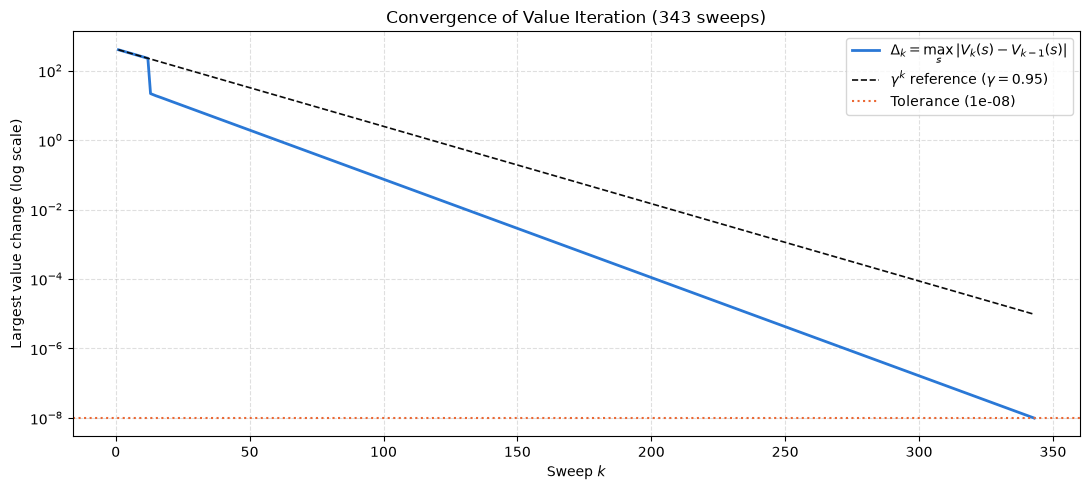

In [10]:
deltas = np.array(vi_solver.deltas)
tail_ratio = np.median(
    deltas[-100:] / deltas[-101:-1]
)  # Per-sweep shrink factor near the end
error_bound = GAMMA * deltas[-1] / (1 - GAMMA)

report(
    f"Delta shrinks by a factor <= gamma per sweep (median ratio over the last 100 sweeps: {tail_ratio:.4f})",
    tail_ratio <= GAMMA + 1e-3,
)
report(
    f"Stopped at delta = {deltas[-1]:.1e} < {vi_solver.tolerance:.0e}; "
    f"guaranteed max |V - V*| <= gamma * delta / (1 - gamma) = {error_bound:.1e}",
    deltas[-1] < vi_solver.tolerance,
)

all_sweeps = np.arange(1, len(deltas) + 1)
fig, ax = plt.subplots(figsize=(11, 5))
ax.semilogy(
    all_sweeps,
    deltas,
    color=BLUE,
    linewidth=2,
    label="$\\Delta_k = \\max_s |V_k(s) - V_{k-1}(s)|$",
)
ax.semilogy(
    all_sweeps,
    deltas[0] * GAMMA ** (all_sweeps - 1),
    color=INK,
    linestyle="--",
    linewidth=1.2,
    label=f"$\\gamma^k$ reference ($\\gamma = {GAMMA}$)",
)
ax.axhline(
    vi_solver.tolerance,
    color=ORANGE,
    linestyle=":",
    linewidth=1.5,
    label=f"Tolerance ({vi_solver.tolerance:.0e})",
)
ax.set(
    title=f"Convergence of Value Iteration ({len(deltas)} sweeps)",
    xlabel="Sweep $k$",
    ylabel="Largest value change (log scale)",
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

### Check 5: How the Q-Values and the Policy Evolve Over the Sweeps
After every sweep $k$, the current values $V_k$ define Q-values and a greedy policy. The heatmap shows the advantage of dispatching, $Q_k(\text{DISPATCH}) - Q_k(\text{WAIT})$, for every sweep and state (blue: dispatch, orange: wait). **Expected:**
- In the first sweep, $V \approx 0$ ignores the future, so waiting (at most $2 \cdot 15 = 30$ per period) always looks cheaper than a dispatch (100): never dispatch.
- As the values start to include more future costs, dispatching becomes attractive and the threshold moves towards 13.
- The policy becomes final long before the values converge, since only the *sign* of the advantage matters for the action. This is the motivation for policy iteration (2c).

[PASS] Greedy policy is final after sweep 35 of 343 (value error at that point: 76.6)


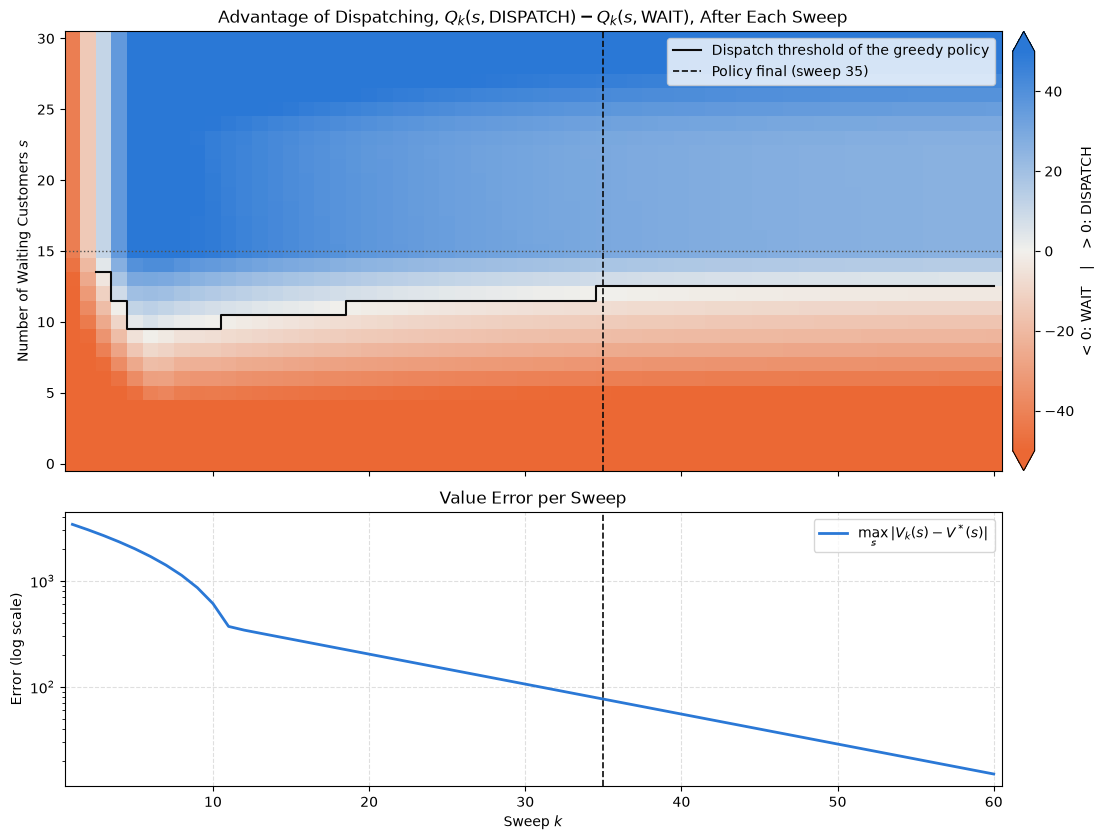

In [11]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

HEATMAP_SWEEPS = 60
HEATMAP_STATES = 30
ADVANTAGE_LIMIT = 50  # Colour scale is clipped at +-50 so the sign change stays visible

history = np.array(vi_solver.history)
sweeps = np.arange(1, len(history) + 1)
value_error = np.abs(history - values).max(axis=1)


def dispatch_advantage(V_k: np.ndarray, s: int) -> float:
    """Q(s, DISPATCH) - Q(s, WAIT) with respect to the values after sweep k."""
    q_k = vi_solver.q_values(s, list(V_k))
    return q_k[ShuttleEnvironmentAction.DISPATCH] - q_k[ShuttleEnvironmentAction.WAIT]


# Greedy policy after every sweep (for s <= 50) and the sweep after which it no longer changes
advantage = np.array(
    [[dispatch_advantage(V_k, s) for s in range(ZOOM_STATE + 1)] for V_k in history]
)
greedy = advantage >= 0
changes = np.flatnonzero((greedy[1:] != greedy[:-1]).any(axis=1))
policy_stable_sweep = int(changes[-1]) + 2 if len(changes) else 1
sweep_threshold = np.array(
    [row.argmax() if row.any() else np.nan for row in greedy], dtype=float
)

report(
    f"Greedy policy is final after sweep {policy_stable_sweep} of {len(history)} "
    f"(value error at that point: {value_error[policy_stable_sweep - 1]:.1f})",
    np.array_equal(greedy[-1], dispatch[: ZOOM_STATE + 1]),
)

fig, (ax_heat, ax_err) = plt.subplots(
    2, 1, figsize=(12, 8.5), sharex=True, height_ratios=(1.6, 1)
)

# Top: advantage of dispatching for every (sweep, state)
cmap = LinearSegmentedColormap.from_list("wait_dispatch", [ORANGE, "#f1f0ec", BLUE])
image = ax_heat.imshow(
    advantage[:HEATMAP_SWEEPS, : HEATMAP_STATES + 1].T,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    norm=TwoSlopeNorm(vmin=-ADVANTAGE_LIMIT, vcenter=0, vmax=ADVANTAGE_LIMIT),
    extent=(0.5, HEATMAP_SWEEPS + 0.5, -0.5, HEATMAP_STATES + 0.5),
)
ax_heat.step(
    sweeps[:HEATMAP_SWEEPS],
    sweep_threshold[:HEATMAP_SWEEPS] - 0.5,
    where="mid",
    color=INK,
    linewidth=1.5,
    label="Dispatch threshold of the greedy policy",
)
ax_heat.axvline(
    policy_stable_sweep,
    color=INK,
    linestyle="--",
    linewidth=1.2,
    label=f"Policy final (sweep {policy_stable_sweep})",
)
ax_heat.axhline(SHUTTLE_CAPACITY, color=MUTED, linestyle=":", linewidth=1)
ax_heat.set(
    title="Advantage of Dispatching, $Q_k(s, \\mathrm{DISPATCH}) - Q_k(s, \\mathrm{WAIT})$, After Each Sweep",
    ylabel="Number of Waiting Customers $s$",
)
ax_heat.legend(loc="upper right")
cbar = fig.colorbar(image, ax=ax_heat, pad=0.01, extend="both")
cbar.set_label("< 0: WAIT    |    > 0: DISPATCH")

# Bottom: the values are still far from converged when the policy is already final
ax_err.semilogy(
    sweeps[:HEATMAP_SWEEPS],
    value_error[:HEATMAP_SWEEPS],
    color=BLUE,
    linewidth=2,
    label="$\\max_s |V_k(s) - V^*(s)|$",
)
ax_err.axvline(policy_stable_sweep, color=INK, linestyle="--", linewidth=1.2)
ax_err.set(
    title="Value Error per Sweep",
    xlabel="Sweep $k$",
    ylabel="Error (log scale)",
    xlim=(0.5, HEATMAP_SWEEPS + 0.5),
)
ax_err.grid(True, linestyle="--", alpha=0.4)
ax_err.legend(loc="upper right")
fig.colorbar(image, ax=ax_err, pad=0.01).ax.set_visible(
    False
)  # Keep both panels aligned

fig.tight_layout()
plt.show()

### Check 6: Simulated Trajectories (Compared With 2a)
The same simulation as in 2a, now with the stationary policy from value iteration. **Expected:**
- Large initial queues are cleared by consecutive dispatches, then every trajectory follows the same sawtooth: build up to the threshold of 13, dispatch.
- Since at most 5 customers arrive per period, every dispatch happens at a queue of 13–17.
- Unlike 2a, there is **no end-of-horizon effect**: the horizon is infinite, so the policy behaves the same at $t = 500$ as at $t = 50$.

Queue at dispatch: 13..17 (mean 14.3)
Periods between dispatches: 3..8 (mean 4.7)
[PASS] Every dispatch happens at a queue of 13..17
[PASS] No end-of-horizon effect: the queue stays <= 17 until t = 500


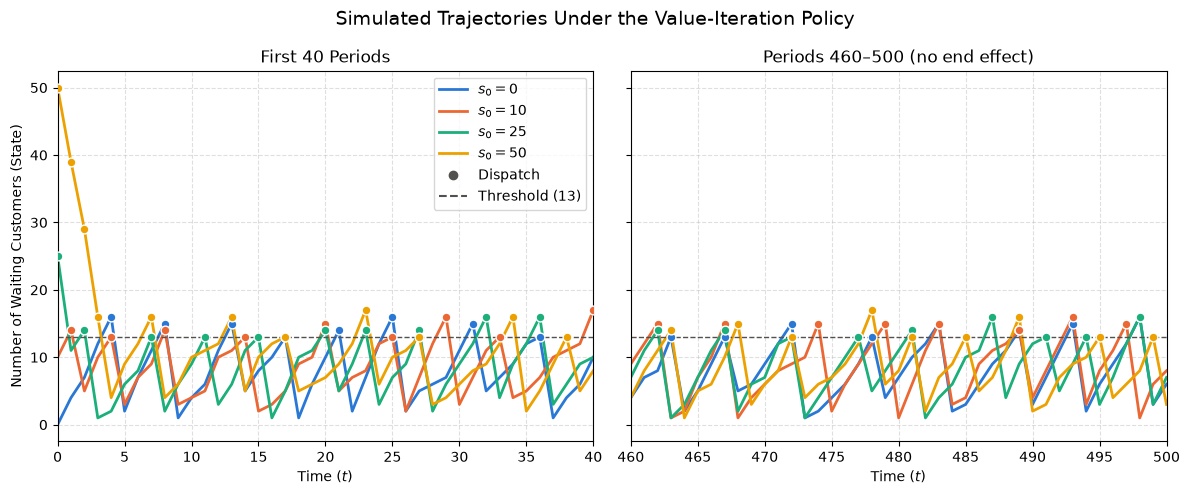

In [12]:
SIM_T = 500
WINDOW = 40
sample_initial_states = [0, 10, 25, 50]
colors = [BLUE, ORANGE, AQUA, "#eda100"]

sim_rng = np.random.default_rng(seed=42)
trajectories, dispatch_times = {}, {}

for s_0 in sample_initial_states:
    state, trajectory, dispatches = s_0, [s_0], []
    for t in range(SIM_T):
        action = vi_solver.get_action(state)
        if action == ShuttleEnvironmentAction.DISPATCH:
            dispatches.append(t)
        probs, next_states_, _ = zip(*shuttle_env.transitions(state, action))
        state = min(int(sim_rng.choice(next_states_, p=probs)), MAX_STATE)
        trajectory.append(state)
    trajectories[s_0] = np.array(trajectory)
    dispatch_times[s_0] = np.array(dispatches, dtype=int)

# Queue size at every dispatch and time between dispatches, after the initial queue is cleared
queue_at_dispatch = np.concatenate(
    [trajectories[s][d[d >= 10]] for s, d in dispatch_times.items()]
)
gaps = np.concatenate([np.diff(d[d >= 10]) for d in dispatch_times.values()])
late_max = max(trajectories[s][10:].max() for s in sample_initial_states)

print(
    f"Queue at dispatch: {queue_at_dispatch.min()}..{queue_at_dispatch.max()} (mean {queue_at_dispatch.mean():.1f})"
)
print(
    f"Periods between dispatches: {gaps.min()}..{gaps.max()} (mean {gaps.mean():.1f})"
)
report(
    f"Every dispatch happens at a queue of {threshold}..{threshold + max(CUSTOMER_ARRIVING_OPTIONS) - 1}",
    queue_at_dispatch.min() >= threshold
    and queue_at_dispatch.max() <= threshold + max(CUSTOMER_ARRIVING_OPTIONS) - 1,
)
report(
    f"No end-of-horizon effect: the queue stays <= {late_max} until t = {SIM_T}",
    late_max <= threshold + max(CUSTOMER_ARRIVING_OPTIONS) - 1,
)

fig, (ax_start, ax_end) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (t_from, t_to), title in (
    (ax_start, (0, WINDOW), f"First {WINDOW} Periods"),
    (
        ax_end,
        (SIM_T - WINDOW, SIM_T),
        f"Periods {SIM_T - WINDOW}–{SIM_T} (no end effect)",
    ),
):
    for s_0, color in zip(sample_initial_states, colors):
        ts = np.arange(t_from, t_to + 1)
        ax.plot(
            ts, trajectories[s_0][ts], color=color, linewidth=2, label=f"$s_0 = {s_0}$"
        )
        d = dispatch_times[s_0]
        d = d[(d >= t_from) & (d <= t_to)]
        ax.scatter(
            d, trajectories[s_0][d], color=color, s=40, zorder=3, edgecolor="white"
        )
    ax.axhline(threshold, linestyle="--", linewidth=1, color=MUTED)
    ax.set(title=title, xlabel="Time ($t$)", xlim=(t_from, t_to))
    ax.grid(True, linestyle="--", alpha=0.4)

ax_start.set_ylabel("Number of Waiting Customers (State)")
ax_start.legend(
    handles=ax_start.get_legend_handles_labels()[0]
    + [
        plt.Line2D([], [], marker="o", linestyle="", color=MUTED, label="Dispatch"),
        plt.Line2D(
            [], [], linestyle="--", color=MUTED, label=f"Threshold ({threshold})"
        ),
    ],
    loc="upper right",
)
fig.suptitle("Simulated Trajectories Under the Value-Iteration Policy", fontsize=14)
fig.tight_layout()
plt.show()

### Check 7: Cross-Check With Enumeration (2a)
Two independent algorithms should agree. Running the enumeration solver from 2a **with the same discount** $\gamma = 0.95$ for a horizon of $n$ periods gives the finite-horizon value $V_0^{(n)}$. Backward induction from $V \equiv 0$ is exactly value iteration started from 0, so **expected:** $V_0^{(n)} \to V^*$ as $n$ grows, with the gap shrinking like $\gamma^n$, and both solvers choose the same action in every state. (One backward induction with $T = 300$ is enough: since the problem is stationary, $V_t$ of that run equals $V_0$ of a problem with horizon $300 - t$.)

[PASS] Gap to V* stays below gamma^n * initial gap for every horizon n (n = 300: 1.4e-04 <= 2.1e-04)
[PASS] Same policy for every s <= 50


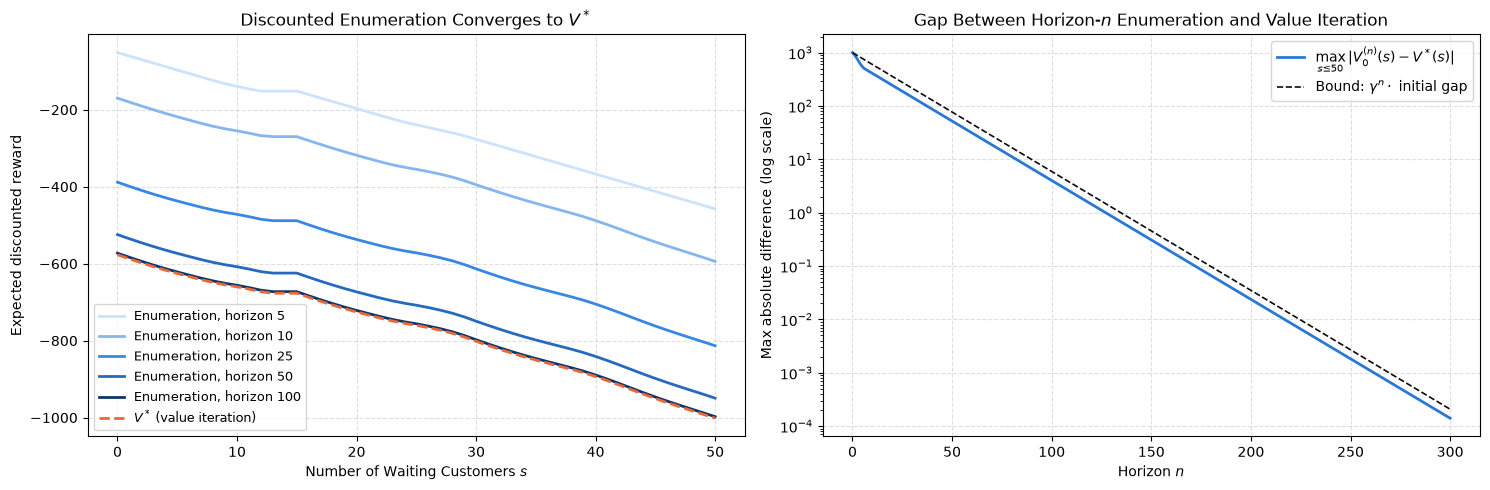

In [13]:
from src.solvers.shuttleenumeration import ShuttleEnumeration

CROSS_T = 300
SHOWN_HORIZONS = [5, 10, 25, 50, 100]

enum_solver = ShuttleEnumeration(
    env=shuttle_env, T=CROSS_T, max_initial_customers_waiting=ZOOM_STATE, gamma=GAMMA
)
enum_solver.solve()

# The problem is stationary, so V_t of a horizon-T problem is V_0 of a horizon-(T - t) problem:
# one backward induction gives the finite-horizon value for every horizon n = 0..T
horizons = np.arange(CROSS_T + 1)
shown = np.arange(ZOOM_STATE + 1)
finite_values = np.array(
    [enum_solver.V[CROSS_T - n][: ZOOM_STATE + 1] for n in horizons]
)
horizon_error = np.abs(finite_values - values[shown]).max(axis=1)
horizon_bound = horizon_error[0] * GAMMA**horizons
enum_dispatch = np.array(
    [
        enum_solver.get_action(int(s), 0) == ShuttleEnvironmentAction.DISPATCH
        for s in shown
    ]
)

report(
    f"Gap to V* stays below gamma^n * initial gap for every horizon n "
    f"(n = {CROSS_T}: {horizon_error[-1]:.1e} <= {horizon_bound[-1]:.1e})",
    np.all(horizon_error <= horizon_bound + 1e-12),
)
report(
    f"Same policy for every s <= {ZOOM_STATE}",
    np.array_equal(enum_dispatch, dispatch[shown]),
)

fig, (ax_v, ax_err) = plt.subplots(1, 2, figsize=(15, 5))

# Left: finite-horizon values approach V* as the horizon grows
horizon_colors = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"]
for n, color in zip(SHOWN_HORIZONS, horizon_colors):
    ax_v.plot(
        shown,
        finite_values[n],
        color=color,
        linewidth=2,
        label=f"Enumeration, horizon {n}",
    )
ax_v.plot(
    shown,
    values[shown],
    color=ORANGE,
    linewidth=2,
    linestyle="--",
    label="$V^*$ (value iteration)",
)
ax_v.set(
    title="Discounted Enumeration Converges to $V^*$",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Expected discounted reward",
)
ax_v.legend(loc="lower left", fontsize=9)

# Right: the gap shrinks like gamma^n
ax_err.semilogy(
    horizons,
    horizon_error,
    color=BLUE,
    linewidth=2,
    label="$\\max_{s \\leq 50} |V_0^{(n)}(s) - V^*(s)|$",
)
ax_err.semilogy(
    horizons,
    horizon_bound,
    color=INK,
    linestyle="--",
    linewidth=1.2,
    label="Bound: $\\gamma^n \\cdot$ initial gap",
)
ax_err.set(
    title="Gap Between Horizon-$n$ Enumeration and Value Iteration",
    xlabel="Horizon $n$",
    ylabel="Max absolute difference (log scale)",
)
ax_err.legend(loc="upper right")

for ax in (ax_v, ax_err):
    ax.grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()

### Check 8: Simulated Returns vs. $V^*$
$V^*(s)$ claims to be the expected discounted reward of the optimal policy from $s$. This can be measured independently by simulating the policy: run 1,000 rollouts from each of several starting states, sum $\gamma^t r_t$ over 400 steps ($\gamma^{400} \approx 10^{-9}$, so the cut-off is negligible), and average. **Expected:** $V^*(s)$ lies inside the confidence interval of the simulated mean, i.e. the standardised difference (z-score) is small for every state.

  s     V*(s)   MC mean  std err      z
  0   -576.67   -577.06     0.98  -0.39
  5   -625.44   -625.90     0.94  -0.49
 10   -660.12   -657.97     0.99   2.18
 13   -676.67   -677.28     0.98  -0.62
 15   -676.67   -676.78     0.98  -0.11
 20   -725.44   -724.74     0.97   0.73
 30   -801.67   -801.78     1.04  -0.11
 40   -893.26   -892.30     1.01   0.95
 50  -1001.53  -1000.91     0.95   0.65
[PASS] V*(s) lies within 3 standard errors of the simulated return for all 9 states


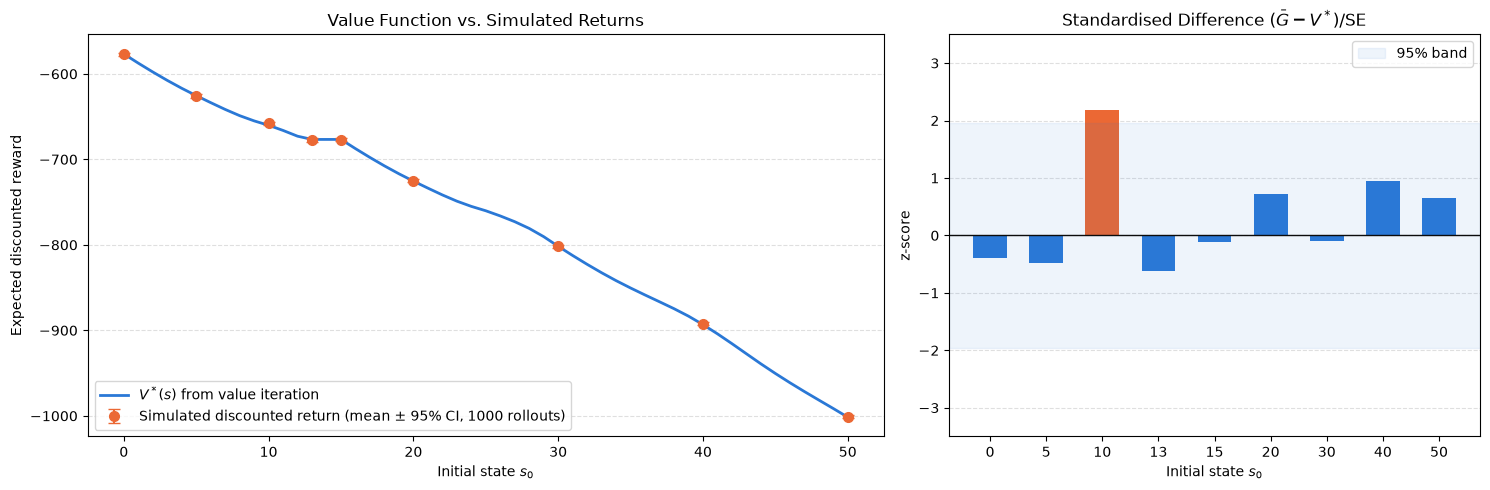

In [14]:
MC_STATES = np.array([0, 5, 10, 13, 15, 20, 30, 40, 50])
MC_ROLLOUTS = 1000
MC_HORIZON = 400  # gamma^400 ~ 1e-9, so cutting the infinite sum here is negligible

mc_rng = np.random.default_rng(seed=0)

# Outcome table from the environment: (state, action) -> probabilities, next states, rewards
actions = (ShuttleEnvironmentAction.WAIT, ShuttleEnvironmentAction.DISPATCH)
outcomes = [[shuttle_env.transitions(s, a) for a in actions] for s in states]
cum_probs = np.array(
    [[np.cumsum([p for p, _, _ in o]) for o in row] for row in outcomes]
)
next_states = np.array(
    [[[min(n, MAX_STATE) for _, n, _ in o] for o in row] for row in outcomes]
)
rewards = np.array([[[r for _, _, r in o] for o in row] for row in outcomes])

mc_means, mc_errors = [], []
for s_0 in MC_STATES:
    state = np.full(MC_ROLLOUTS, s_0)
    total = np.zeros(MC_ROLLOUTS)
    for t in range(MC_HORIZON):
        a = dispatch[state].astype(int)  # Optimal action from value iteration
        outcome = (mc_rng.random(MC_ROLLOUTS)[:, None] > cum_probs[state, a]).sum(
            axis=1
        )
        total += GAMMA**t * rewards[state, a, outcome]
        state = next_states[state, a, outcome]
    mc_means.append(total.mean())
    mc_errors.append(total.std(ddof=1) / np.sqrt(MC_ROLLOUTS))

mc_means, mc_errors = np.array(mc_means), np.array(mc_errors)
z_scores = (mc_means - values[MC_STATES]) / mc_errors

print(f"{'s':>3} {'V*(s)':>9} {'MC mean':>9} {'std err':>8} {'z':>6}")
for s, v, m, e, z in zip(MC_STATES, values[MC_STATES], mc_means, mc_errors, z_scores):
    print(f"{s:>3} {v:>9.2f} {m:>9.2f} {e:>8.2f} {z:>6.2f}")
report(
    f"V*(s) lies within 3 standard errors of the simulated return for all {len(MC_STATES)} states",
    np.all(np.abs(z_scores) < 3),
)

fig, (ax_v, ax_z) = plt.subplots(1, 2, figsize=(15, 5), width_ratios=(1.5, 1))

shown = np.arange(ZOOM_STATE + 1)
ax_v.plot(
    shown, values[shown], color=BLUE, linewidth=2, label="$V^*(s)$ from value iteration"
)
ax_v.errorbar(
    MC_STATES,
    mc_means,
    yerr=1.96 * mc_errors,
    fmt="o",
    color=ORANGE,
    markersize=7,
    capsize=4,
    label=f"Simulated discounted return (mean ± 95% CI, {MC_ROLLOUTS} rollouts)",
)
ax_v.set(
    title="Value Function vs. Simulated Returns",
    xlabel="Initial state $s_0$",
    ylabel="Expected discounted reward",
)
ax_v.legend(loc="lower left")

ax_z.bar(
    MC_STATES.astype(str),
    z_scores,
    color=np.where(np.abs(z_scores) < 1.96, BLUE, ORANGE),
    width=0.6,
)
ax_z.axhspan(-1.96, 1.96, color=BLUE, alpha=0.08, label="95% band")
ax_z.axhline(0, color=INK, linewidth=1)
ax_z.set(
    title="Standardised Difference $(\\bar{G} - V^*) / \\mathrm{SE}$",
    xlabel="Initial state $s_0$",
    ylabel="z-score",
    ylim=(-3.5, 3.5),
)
ax_z.legend(loc="upper right")

for ax in (ax_v, ax_z):
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Edge-Case Checks: State Cap and Discount Factor
- **Cap at 200 customers:** next states above `MAX_STATE` are clamped (extra customers are turned away). This must not influence the states that actually occur. **Expected:** doubling the cap to 400 leaves $V^*$ on $s \leq 50$ unchanged.
- **Discount factor:** value iteration only converges for $0 \leq \gamma < 1$. **Expected:** $\gamma = 1$, $\gamma > 1$ and $\gamma < 0$ are rejected with a `ValueError`.

In [15]:
LARGER_MAX_STATE = 400

larger_solver = ShuttleValueIteration(
    env=shuttle_env, max_state=LARGER_MAX_STATE, gamma=GAMMA
)
larger_solver.solve()
cap_difference = np.abs(
    np.array(larger_solver.V[: ZOOM_STATE + 1]) - values[: ZOOM_STATE + 1]
).max()

report(
    f"Cap {MAX_STATE} vs. {LARGER_MAX_STATE}: same V on s <= {ZOOM_STATE} (max difference {cap_difference:.1e})",
    cap_difference < 1e-6,
)

for invalid_gamma in (1.0, 1.5, -0.1):
    try:
        ShuttleValueIteration(env=shuttle_env, max_state=MAX_STATE, gamma=invalid_gamma)
        report(f"gamma = {invalid_gamma} is rejected", False)
    except ValueError:
        report(f"gamma = {invalid_gamma} is rejected", True)

[PASS] Cap 200 vs. 400: same V on s <= 50 (max difference 0.0e+00)
[PASS] gamma = 1.0 is rejected
[PASS] gamma = 1.5 is rejected
[PASS] gamma = -0.1 is rejected
